In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (classification_report, confusion_matrix,
                             roc_auc_score, average_precision_score,
                             precision_recall_curve, precision_recall_fscore_support)

sns.set_theme(style="whitegrid")

df = pd.read_csv("../data/banksim_clean.csv")
df["category"] = df["category"].replace({"Otherservices": "Other Services",
                                         "Hotelservices": "Hotel Services"})
df.shape

(594643, 13)

In [2]:
FEATURES = ["amount", "category", "age_group", "gender"]
TARGET = "fraud"

X = df[FEATURES]
y = df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

print("Train:", X_train.shape, " Test:", X_test.shape)
print("Fraud % in train:", round(y_train.mean() * 100, 2))
print("Fraud % in test :", round(y_test.mean() * 100, 2))

Train: (475714, 4)  Test: (118929, 4)
Fraud % in train: 1.21
Fraud % in test : 1.21


In [12]:
num_cols = ["amount"]
cat_cols = ["category", "age_group", "gender"]

def make_preprocessor(scale):
    return ColumnTransformer([
        ("num", StandardScaler() if scale else "passthrough", num_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
    ])

log_reg = Pipeline([
    ("prep", make_preprocessor(scale=True)),
    ("model", LogisticRegression(class_weight="balanced", max_iter=1000)),
])

rand_forest = Pipeline([
    ("prep", make_preprocessor(scale=False)),
    ("model", RandomForestClassifier(
        n_estimators=100, max_depth=12, min_samples_leaf=5,
        class_weight="balanced_subsample", n_jobs=-1, random_state=42)),
])

In [4]:
results = {}
for name, model in [("Logistic Regression", log_reg), ("Random Forest", rand_forest)]:
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    proba = model.predict_proba(X_test)[:, 1]
    p, r, f, _ = precision_recall_fscore_support(y_test, pred, average="binary")
    results[name] = {"precision": p, "recall": r, "f1": f,
                     "roc_auc": roc_auc_score(y_test, proba),
                     "pr_auc": average_precision_score(y_test, proba)}
    print(f"\n=== {name} ===")
    print(confusion_matrix(y_test, pred))

pd.DataFrame(results).T.round(3)


=== Logistic Regression ===
[[109405   8084]
 [    23   1417]]

=== Random Forest ===
[[110872   6617]
 [    45   1395]]


,precision,recall,f1,roc_auc,pr_auc
Logistic Regression,0.149,0.984,0.259,0.992,0.775
Random Forest,0.174,0.969,0.295,0.992,0.768


In [5]:
proba = rand_forest.predict_proba(X_test)[:, 1]

rows = []
for t in [0.5, 0.6, 0.7, 0.8, 0.85, 0.9, 0.95]:
    pred_t = (proba >= t).astype(int)
    p, r, f, _ = precision_recall_fscore_support(y_test, pred_t, average="binary", zero_division=0)
    rows.append({"threshold": t, "precision": p, "recall": r, "f1": f,
                 "flagged": pred_t.sum()})

pd.DataFrame(rows).round(3)

,threshold,precision,recall,f1,flagged
0,0.50,0.174,0.969,0.295,8012
1,0.60,0.232,0.940,0.373,5828
2,0.70,0.321,0.884,0.471,3971
3,0.80,0.455,0.806,0.581,2552
4,0.85,0.567,0.775,0.655,1969
5,0.90,0.680,0.730,0.704,1545
6,0.95,0.824,0.643,0.722,1124


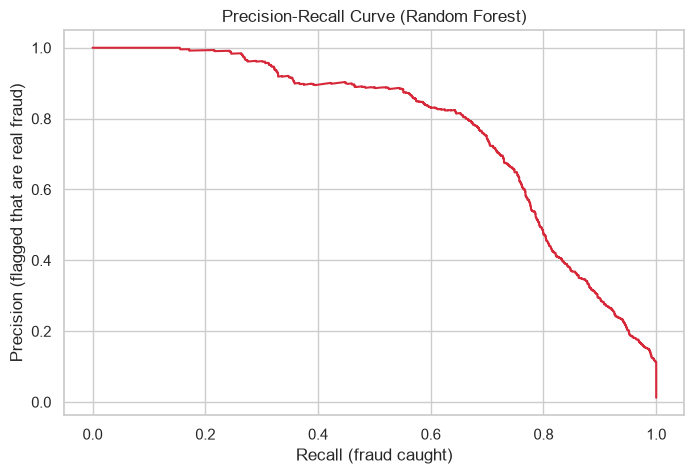

In [6]:
prec, rec, thr = precision_recall_curve(y_test, proba)

plt.figure(figsize=(8, 5))
plt.plot(rec, prec, color="#d62839")
plt.xlabel("Recall (fraud caught)")
plt.ylabel("Precision (flagged that are real fraud)")
plt.title("Precision-Recall Curve (Random Forest)")
plt.savefig("../images/precision_recall_curve.png", dpi=150, bbox_inches="tight")
plt.show()

In [7]:
THRESHOLD = 0.9
final_pred = (proba >= THRESHOLD).astype(int)
print(classification_report(y_test, final_pred, target_names=["Normal", "Fraud"]))
print(confusion_matrix(y_test, final_pred))

              precision    recall  f1-score   support

      Normal       1.00      1.00      1.00    117489
       Fraud       0.68      0.73      0.70      1440

    accuracy                           0.99    118929
   macro avg       0.84      0.86      0.85    118929
weighted avg       0.99      0.99      0.99    118929

[[116995    494]
 [   389   1051]]


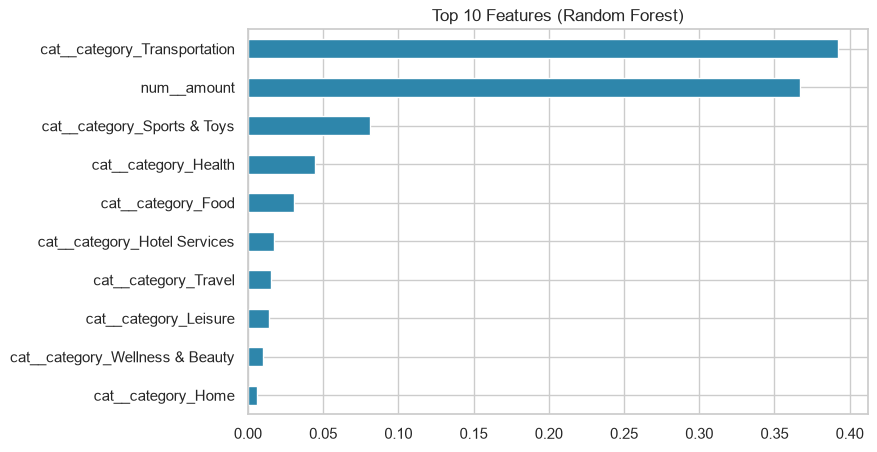

In [8]:
names = rand_forest.named_steps["prep"].get_feature_names_out()
importance = (pd.Series(rand_forest.named_steps["model"].feature_importances_, index=names)
                .sort_values(ascending=False))

importance.head(10).sort_values().plot(kind="barh", figsize=(8, 5), color="#2e86ab")
plt.title("Top 10 Features (Random Forest)")
plt.savefig("../images/feature_importance.png", dpi=150, bbox_inches="tight")
plt.show()

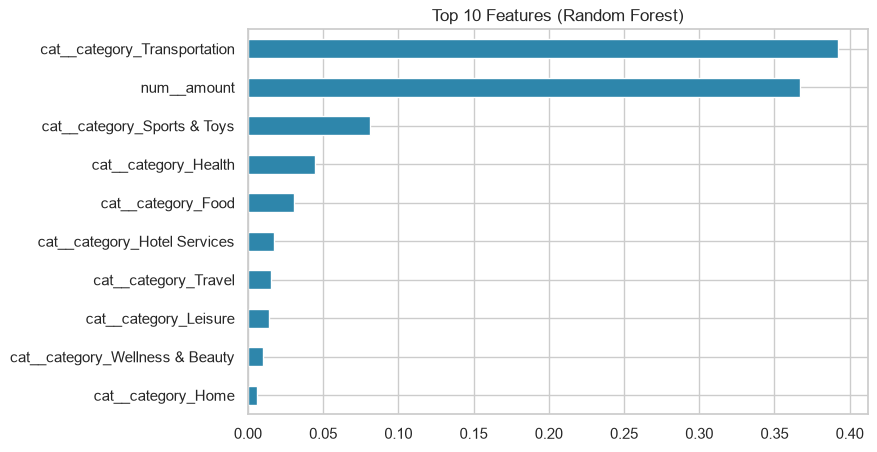

In [9]:
names = rand_forest.named_steps["prep"].get_feature_names_out()
importance = (pd.Series(rand_forest.named_steps["model"].feature_importances_, index=names)
                .sort_values(ascending=False))

importance.head(10).sort_values().plot(kind="barh", figsize=(8, 5), color="#2e86ab")
plt.title("Top 10 Features (Random Forest)")
plt.savefig("../images/feature_importance.png", dpi=150, bbox_inches="tight")
plt.show()

In [10]:
import os
os.makedirs("../models", exist_ok=True)

joblib.dump({"pipeline": rand_forest, "threshold": THRESHOLD, "features": FEATURES},
            "../models/fraud_model.pkl", compress=3)

print("Model size (MB):", round(os.path.getsize("../models/fraud_model.pkl") / 1e6, 1))

Model size (MB): 2.0
